In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay
)

In [4]:
df = pd.read_excel(
    r"C:\Users\MTC\Desktop\RetailPulse\data\processed\retail_clean.xlsx"
)
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,IsCancellation,Revenue,TransactionType,Year,Month,Day,DayOfWeek,YearMonth,Date
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,False,15.30,Normal Sale,2010,12,1,2,2010-12,2010-12-01
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,20.34,Normal Sale,2010,12,1,2,2010-12,2010-12-01
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,False,22.00,Normal Sale,2010,12,1,2,2010-12,2010-12-01
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,20.34,Normal Sale,2010,12,1,2,2010-12,2010-12-01
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,20.34,Normal Sale,2010,12,1,2,2010-12,2010-12-01


In [5]:
print("Dataset start:", df["InvoiceDate"].min())
print("Dataset end:", df["InvoiceDate"].max())

print(
    "Unique customers:",
    df["Customer ID"].nunique()
)

print(
    "Missing customer IDs:",
    df["Customer ID"].isna().sum()
)

Dataset start: 2010-12-01 08:26:00
Dataset end: 2011-12-09 12:50:00
Unique customers: 4372
Missing customer IDs: 135037


Here a customer is labelled as churned if they make no qualifying purchase during the 90 days after a chosen observation date

In [6]:
# Define the observation cutoff
cutoff_date = (
    df["InvoiceDate"].max().normalize()
    - pd.Timedelta(days=90)
)

print("Observation cutoff:", cutoff_date)
print(
    "Last date available:",
    df["InvoiceDate"].max()
)

Observation cutoff: 2011-09-10 00:00:00
Last date available: 2011-12-09 12:50:00


In [7]:
# Creating observations and prediction windows

observation_start = (
    cutoff_date - pd.DateOffset(years=1)
)

prediction_end = cutoff_date + pd.Timedelta(days=90)

print("Observation starts:", observation_start)
print("Observation ends:", cutoff_date)
print("Prediction ends:", prediction_end)

Observation starts: 2010-09-10 00:00:00
Observation ends: 2011-09-10 00:00:00
Prediction ends: 2011-12-09 00:00:00


In [8]:
# Separtating 2 periods

valid_sales = df[
    (df["Quantity"] > 0) &
    (df["Price"] > 0) &
    (df["Customer ID"].notna())
].copy()

observation_sales = valid_sales[
    (valid_sales["InvoiceDate"] < cutoff_date) &
    (valid_sales["InvoiceDate"] >= observation_start)
].copy()

future_sales = valid_sales[
    (valid_sales["InvoiceDate"] >= cutoff_date) &
    (valid_sales["InvoiceDate"] < prediction_end)
].copy()

print("Observation transactions:", len(observation_sales))
print("Future transactions:", len(future_sales))

Observation transactions: 233840
Future transactions: 158242


In [9]:
print(
    "Observation period:",
    observation_sales["InvoiceDate"].min(),
    "to",
    observation_sales["InvoiceDate"].max()
)

print(
    "Future period:",
    future_sales["InvoiceDate"].min(),
    "to",
    future_sales["InvoiceDate"].max()
)

Observation period: 2010-12-01 08:26:00 to 2011-09-09 15:53:00
Future period: 2011-09-11 10:35:00 to 2011-12-08 20:01:00


In [11]:
observation_sales["Revenue"] = (
    observation_sales["Quantity"] *
    observation_sales["Price"]
)

customer_features = (
    observation_sales
    .groupby("Customer ID")
    .agg(
        LastPurchase=("InvoiceDate", "max"),
        Frequency=("Invoice", "nunique"),
        Monetary=("Revenue", "sum"),
        TotalQuantity=("Quantity", "sum")
    )
)

In [12]:
future_customers = future_sales["Customer ID"].unique()

customer_features["Churn"] = (
    ~customer_features.index.isin(future_customers)
).astype(int)

In [13]:
customer_features["Churn"].value_counts()

Churn
0    1919
1    1451
Name: count, dtype: int64

In [14]:
customer_features["Churn"].value_counts(normalize=True).mul(100).round(2)

Churn
0    56.94
1    43.06
Name: proportion, dtype: float64

In [15]:
# Model features

customer_features["Recency"] = (
    cutoff_date - customer_features["LastPurchase"]
).dt.days

In [16]:
customer_features[
    [
        "Recency",
        "Frequency",
        "Monetary",
        "TotalQuantity",
        "Churn"
    ]
].head()

,Recency,Frequency,Monetary,TotalQuantity,Churn
Customer ID,,,,,
12346.0,234,1,77183.60,74215,1
12347.0,38,5,2790.86,1590,0
12348.0,157,3,1487.24,2124,0
12350.0,219,1,334.40,197,1
12352.0,171,5,1561.81,254,0


In [17]:
features = [
    "Recency",
    "Frequency",
    "Monetary",
    "TotalQuantity"
]

print(customer_features[features].isna().sum())
print(np.isinf(customer_features[features]).sum())

Recency          0
Frequency        0
Monetary         0
TotalQuantity    0
dtype: int64
Recency          0
Frequency        0
Monetary         0
TotalQuantity    0
dtype: int64


In [18]:
X = customer_features[features].copy()
y = customer_features["Churn"].copy()

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (3370, 4)
Target shape: (3370,)


In [19]:
# Splitting data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training customers:", len(X_train))
print("Testing customers:", len(X_test))

Training customers: 2696
Testing customers: 674


In [20]:
# Scale features

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [21]:
# Training logistic regression model
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [22]:

# Predictions

y_pred = model.predict(X_test_scaled)

y_prob = model.predict_proba(X_test_scaled)[:, 1]

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.69      0.68      0.69       384
           1       0.58      0.60      0.59       290

    accuracy                           0.64       674
   macro avg       0.64      0.64      0.64       674
weighted avg       0.64      0.64      0.64       674



In [23]:
print(confusion_matrix(y_test, y_pred))

print(
    "ROC-AUC:",
    round(roc_auc_score(y_test, y_prob), 3)
)

[[261 123]
 [117 173]]
ROC-AUC: 0.715


In [24]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
})

feature_importance["Absolute_Coefficient"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

,Feature,Coefficient,Absolute_Coefficient
1,Frequency,-1.950308,1.950308
0,Recency,0.336184,0.336184
2,Monetary,0.069277,0.069277
3,TotalQuantity,-0.049485,0.049485


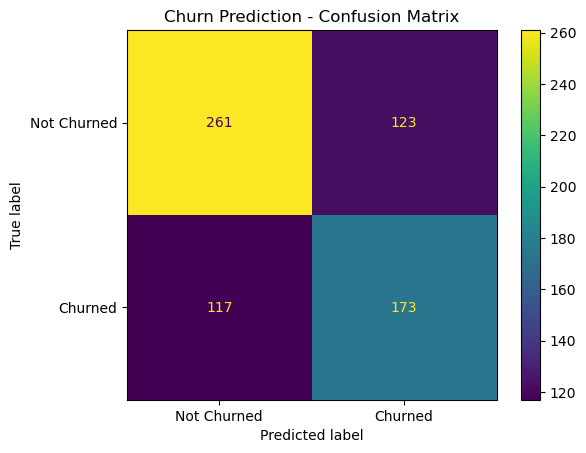

In [25]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Churned", "Churned"]
)

disp.plot()
plt.title("Churn Prediction - Confusion Matrix")
plt.show()

In [26]:
# Number of customers to target (top 20%)
top_n = int(np.ceil(len(y_test) * 0.20))

# Rank customers by predicted churn probability
results = pd.DataFrame({
    "Actual_Churn": y_test.to_numpy(),
    "Churn_Probability": y_prob
})

results = results.sort_values(
    "Churn_Probability",
    ascending=False
)

# Select the 20% highest-risk customers
top_customers = results.head(top_n)

precision_at_20 = top_customers["Actual_Churn"].mean()

print("Customers selected:", top_n)
print(f"Precision@Top 20%: {precision_at_20:.3f}")
print(f"Target: 0.750")

Customers selected: 135
Precision@Top 20%: 0.674
Target: 0.750


In [27]:
# Create order-level data from the observation period
orders = (
    observation_sales
    .groupby(["Customer ID", "Invoice"])
    .agg(
        OrderDate=("InvoiceDate", "max"),
        OrderRevenue=("Revenue", "sum"),
        OrderQuantity=("Quantity", "sum")
    )
    .reset_index()
)

# Calculate additional customer features
extra_features = orders.groupby("Customer ID").agg(
    AvgOrderValue=("OrderRevenue", "mean"),
    AvgOrderQuantity=("OrderQuantity", "mean"),
    ActivePurchaseDays=("OrderDate", "nunique")
)

# Join new features to existing customer features
customer_features = customer_features.join(extra_features)

customer_features[
    ["AvgOrderValue", "AvgOrderQuantity", "ActivePurchaseDays"]
].head()

,AvgOrderValue,AvgOrderQuantity,ActivePurchaseDays
Customer ID,,,
12346.0,77183.600000,74215.0,1
12347.0,558.172000,318.0,5
12348.0,495.746667,708.0,3
12350.0,334.400000,197.0,1
12352.0,312.362000,50.8,5


In [39]:
from sklearn.base import clone
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

# Reuse the existing customer-level split; keep test data out of model and threshold selection.
model_features = [
    "Recency",
    "Frequency",
    "Monetary",
    "TotalQuantity",
    "AvgOrderValue",
    "AvgOrderQuantity",
    "ActivePurchaseDays",
    "RecentInvoices",
    "PreviousInvoices",
    "InvoiceChange",
]

X_model = customer_features[model_features].replace([np.inf, -np.inf], np.nan)
X_train_model = X_model.loc[X_train.index]
X_test_model = X_model.loc[X_test.index]

candidates = {
    "Logistic Regression": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=42),
    ),
    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(
            n_estimators=400,
            min_samples_leaf=3,
            max_features="sqrt",
            random_state=42,
            n_jobs=1,
        ),
    ),
    "Extra Trees": make_pipeline(
        SimpleImputer(strategy="median"),
        ExtraTreesClassifier(
            n_estimators=400,
            min_samples_leaf=3,
            max_features="sqrt",
            random_state=42,
            n_jobs=1,
        ),
    ),
    "Hist Gradient Boosting": make_pipeline(
        SimpleImputer(strategy="median"),
        HistGradientBoostingClassifier(
            max_iter=200,
            learning_rate=0.05,
            max_leaf_nodes=15,
            l2_regularization=1.0,
            random_state=42,
        ),
    ),
    "XGBoost": make_pipeline(
        SimpleImputer(strategy="median"),
        XGBClassifier(
            n_estimators=400,
            max_depth=3,
            learning_rate=0.03,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=5,
            eval_metric="logloss",
            random_state=42,
            n_jobs=1,
        ),
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
thresholds = np.arange(0.05, 0.951, 0.01)
cv_results = []

for name, candidate in candidates.items():
    oof_probabilities = cross_val_predict(
        candidate,
        X_train_model,
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=1,
    )[:, 1]
    threshold_accuracies = [
        accuracy_score(y_train, oof_probabilities >= threshold)
        for threshold in thresholds
    ]
    best_index = int(np.argmax(np.asarray(threshold_accuracies, dtype=float)))
    cv_results.append({
        "Model": name,
        "CV_Accuracy": threshold_accuracies[best_index],
        "Threshold": thresholds[best_index],
        "CV_ROC_AUC": roc_auc_score(y_train, oof_probabilities),
    })

cv_results = pd.DataFrame(cv_results).sort_values(
    ["CV_Accuracy", "CV_ROC_AUC"], ascending=False
).reset_index(drop=True)
print("Training-only cross-validation results:")
display(cv_results)

best_name = str(cv_results["Model"].iloc[0])
best_threshold = float(cv_results["Threshold"].astype(float).iloc[0])
best_model = clone(candidates[best_name])
best_model.fit(X_train_model, y_train)

test_probabilities = best_model.predict_proba(X_test_model)[:, 1]
test_predictions = (test_probabilities >= best_threshold).astype(int)
test_accuracy = accuracy_score(y_test, test_predictions)

test_metrics = pd.Series({
    "Selected model": best_name,
    "Training-CV threshold": best_threshold,
    "Test accuracy": test_accuracy,
    "Test ROC-AUC": roc_auc_score(y_test, test_probabilities),
    "88% accuracy target met": test_accuracy >= 0.88,
})
print("\nHeld-out test results:")
display(test_metrics)
print("\nClassification report:")
print(classification_report(y_test, test_predictions, zero_division=0))
print("Confusion matrix:")
print(confusion_matrix(y_test, test_predictions))

Training-only cross-validation results:


,Model,CV_Accuracy,Threshold,CV_ROC_AUC
0,Logistic Regression,0.680267,0.48,0.737674
1,Extra Trees,0.671365,0.48,0.729641
2,XGBoost,0.670623,0.44,0.735435
3,Hist Gradient Boosting,0.657270,0.49,0.719018
4,Random Forest,0.655415,0.39,0.706545



Held-out test results:


Selected model             Logistic Regression
Training-CV threshold                     0.48
Test accuracy                         0.643917
Test ROC-AUC                           0.71197
88% accuracy target met                  False
dtype: object


Classification report:
              precision    recall  f1-score   support

           0       0.72      0.62      0.66       384
           1       0.57      0.68      0.62       290

    accuracy                           0.64       674
   macro avg       0.65      0.65      0.64       674
weighted avg       0.66      0.64      0.65       674

Confusion matrix:
[[237 147]
 [ 93 197]]
